## Testing Pripps-py for Lysozyme

In [2]:
import numpy as np
import pripps
from scipy.optimize import minimize
import matplotlib.pyplot as plt

In [3]:
pr = pripps.Pripps(atomfile="/Users/isabelvinterbladh/Documents/HALRIC/pripps/assets/poly_amino_acid.yaml")
model = pr.multipole_model(
    structure_file="/Users/isabelvinterbladh/Documents/HALRIC/pripps/tests/lysozyme/6lyz.xyz",
    qmin=0.0,
    qmax=0.5,
    nq=196,
    excluded="per-kind",
    volume_scale=1.0,        # fit knob c₁ (scales excluded volume)
    hydration="sasa",        # FoXS-style SASA-weighted hydration shell
    probe=1.8,               # SASA probe radius (Å)
    contrast_density=0.03,   # fit knob c₂ (scales hydration)
    bulk_electron_density=0.334,  # e/Å³, pure water
)

# Returns a dict of numpy arrays
out = model.intensity(volume_scale=1.0, contrast_density=0.03)

OSError: assets/poly_atev.yaml: No such file or directory (os error 2)

In [4]:
# experimental data: q (Å⁻¹), I(q), σ(q)
data = np.loadtxt("/Users/isabelvinterbladh/Documents/HALRIC/pripps/tests/lysozyme/lyzexp.dat", comments="#")
q_exp, i_exp, sigma = data[:, 0], data[:, 1], data[:, 2]

def chi2(params):
    c1, c2 = params
    out = model.intensity(volume_scale=c1, contrast_density=c2)
    theory = np.interp(q_exp, out["q"], out["total"])
    scale = np.sum(theory * i_exp / sigma**2) / np.sum((theory / sigma) ** 2)
    return np.sum(((scale * theory - i_exp) / sigma) ** 2) / len(q_exp)

result = minimize(
    chi2,
    x0=[1.0, 0.2],
    bounds=[(0.95, 1.12), (-2.0, 4.0)],
    method="L-BFGS-B",
)
print(f"c1={result.x[0]:.4f}, c2={result.x[1]:.4f}, χ²/N={result.fun:.4f}")

c1=1.0304, c2=0.0734, χ²/N=0.2205


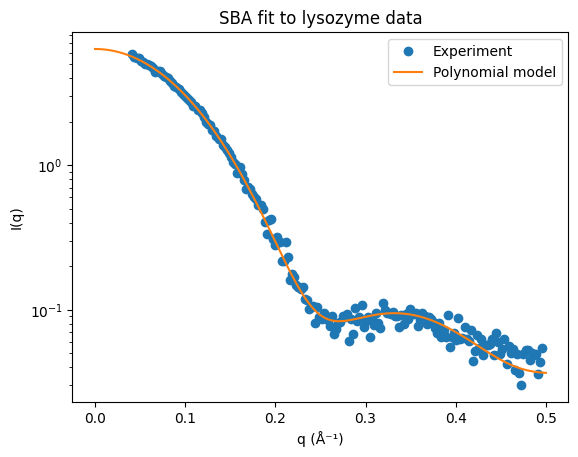

In [5]:
out2 = model.intensity(volume_scale=result.x[0], contrast_density=result.x[1])
theory = np.interp(q_exp, out2["q"], out2["total"])
scale = np.sum(theory * i_exp / sigma**2) / np.sum((theory / sigma) ** 2)
plt.plot(q_exp, i_exp, "o", label="Experiment")
plt.plot(out2["q"], scale*out2["total"], label="Polynomial model")
plt.legend()
plt.xlabel("q (Å⁻¹)")
plt.ylabel("I(q)")
plt.yscale("log")
#plt.xscale("log")
plt.title("SBA fit to lysozyme data")
plt.savefig("/Users/isabelvinterbladh/Documents/HALRIC/pripps/tests/lysozyme/sba_fit_excl+hydration.pdf")
plt.show()

In [7]:
pr = pripps.Pripps(atomfile="/Users/isabelvinterbladh/Documents/HALRIC/pripps/assets/poly_amino_acid.yaml")
model = pr.multipole_model(
    structure_file="/Users/isabelvinterbladh/Documents/HALRIC/pripps/tests/lysozyme/6lyz.xyz",
    qmin=0.0,
    qmax=0.5,
    nq=196,
    excluded="fraser",  # FoXS-style excluded volume (16π Fraser)
    volume_scale=1.0,        # fit knob c₁ (scales excluded volume)
    hydration="sasa",        # FoXS-style SASA-weighted hydration shell
    probe=1.8,               # SASA probe radius (Å)
    contrast_density=0.03,   # fit knob c₂ (scales hydration)
    bulk_electron_density=0.334,  # e/Å³, pure water
)

# Returns a dict of numpy arrays
out = model.intensity(volume_scale=1.0, contrast_density=0.03)
print(out["q"][:3], out["total"][:3])

[0.         0.0025641  0.00512821] [260710.30492072 260534.6764846  260001.94048118]


In [8]:
# experimental data: q (Å⁻¹), I(q), σ(q)
data = np.loadtxt("/Users/isabelvinterbladh/Documents/HALRIC/pripps/tests/lysozyme/lyzexp.dat", comments="#")
q_exp, i_exp, sigma = data[:, 0], data[:, 1], data[:, 2]

def chi2(params):
    c1, c2 = params
    out = model.intensity(volume_scale=c1, contrast_density=c2)
    theory = np.interp(q_exp, out["q"], out["total"])
    scale = np.sum(theory * i_exp / sigma**2) / np.sum((theory / sigma) ** 2)
    return np.sum(((scale * theory - i_exp) / sigma) ** 2) / len(q_exp)

result = minimize(
    chi2,
    x0=[1.0, 0.2],
    bounds=[(0.95, 1.12), (-2.0, 4.0)],
    method="L-BFGS-B",
)
print(f"c1={result.x[0]:.4f}, c2={result.x[1]:.4f}, χ²/N={result.fun:.4f}")

c1=0.9500, c2=4.0000, χ²/N=10.6151


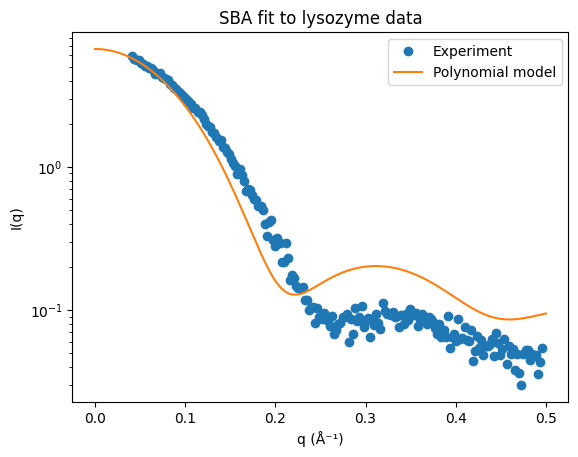

In [9]:
out2 = model.intensity(volume_scale=result.x[0], contrast_density=result.x[1])
theory = np.interp(q_exp, out2["q"], out2["total"])
scale = np.sum(theory * i_exp / sigma**2) / np.sum((theory / sigma) ** 2)
plt.plot(q_exp, i_exp, "o", label="Experiment")
plt.plot(out2["q"], scale*out2["total"], label="Polynomial model")
plt.legend()
plt.xlabel("q (Å⁻¹)")
plt.ylabel("I(q)")
plt.yscale("log")
#plt.xscale("log")
plt.title("SBA fit to lysozyme data")
#plt.savefig("/Users/isabelvinterbladh/Documents/HALRIC/pripps/tests/lysozyme/sba_fit_no_hydration.pdf")
plt.show()